# 1. Exploración de Datos — Predicting Credit Card Fraud

Primer recorrido por el dataset del episodio, antes de modelar. El objetivo es contestar tres cosas:

- **¿Dónde está la señal?** Qué variables discriminan de verdad y cuáles son ruido.
- **¿Qué forma tiene?** Si las relaciones son monótonas o hay umbrales y niveles con comportamiento especial.
- **¿Hay interacciones?** Efectos que cambian según el nivel de otra variable.

**Métrica:** ROC AUC (se predice la probabilidad de `is_fraud`).
**Dataset:** Playground Series S6E11

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 6)
plt.rcParams["figure.dpi"] = 100

SEED = 42

In [2]:
train = pd.read_csv("../data/train.csv")
test  = pd.read_csv("../data/test.csv")

TARGET = "is_fraud"

continuas = ["amount_usd", "hours_since_last_txn", "distance_from_home_km", "card_age_months",
             "customer_age", "account_balance_usd", "velocity_score", "merchant_risk_score"]
discretas = ["txn_count_last_24h", "cvv_retry_count", "prior_disputes", "time_of_day_hour", "day_of_week"]
binarias = ["is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch",
            "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]
categoricas = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
numericas = continuas + discretas
feats = numericas + binarias + categoricas

# Version entera del target y de las binarias para promedios y AUC
train["y"] = train[TARGET].astype(int)
for df in (train, test):
    df[binarias] = df[binarias].astype(int)

print(f"Train: {train.shape[0]:,} filas x {train.shape[1] - 1} columnas")
print(f"Test:  {test.shape[0]:,} filas x {test.shape[1]} columnas")
print(f"Continuas: {len(continuas)} | Discretas: {len(discretas)} | Binarias: {len(binarias)} | Categoricas: {len(categoricas)}")

Train: 699,960 filas x 26 columnas
Test:  299,984 filas x 25 columnas
Continuas: 8 | Discretas: 5 | Binarias: 6 | Categoricas: 5


## 2. Visión General del Dataset

In [3]:
train.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,y
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,POS,iPhone,0,0,0,0,0,0,0.0,0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,In-App,Android Phone,0,0,0,0,0,0,0.0,0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,Online,Tablet,0,0,1,0,0,0,0.0,0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,POS,Android Phone,0,0,0,0,0,0,0.0,0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,Online,Windows PC,0,0,0,0,0,0,0.0,0


In [4]:
train.drop(columns='y').info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [5]:
train[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
merchant_risk_score,699960.0,35.217648,12.628361,0.00,26.40,34.20,42.70,100.00
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00


In [6]:
print("Valores nulos por columna (solo las que tienen alguno):")
nulos = pd.DataFrame({"train": train[feats].isna().sum(), "test": test[feats].isna().sum()})
print(nulos[nulos.sum(axis=1) > 0].to_string() if nulos.values.sum() else "  ninguno")
print(f"\nFilas duplicadas (ignorando id y target): {train.duplicated(subset=feats).sum():,}")
print(f"ids unicos en train: {train['id'].is_unique} | en test: {test['id'].is_unique}")
print(f"Valores del target: {sorted(train[TARGET].unique())}")

Valores nulos por columna (solo las que tienen alguno):


  ninguno



Filas duplicadas (ignorando id y target): 0
ids unicos en train: True | en test: True
Valores del target: [np.float64(0.0), np.float64(1.0)]


Dataset limpio: sin nulos, sin duplicados e ids únicos. El target viene como float (`0.0` / `1.0`) y las seis binarias como booleanos.

## 3. Distribución del Target

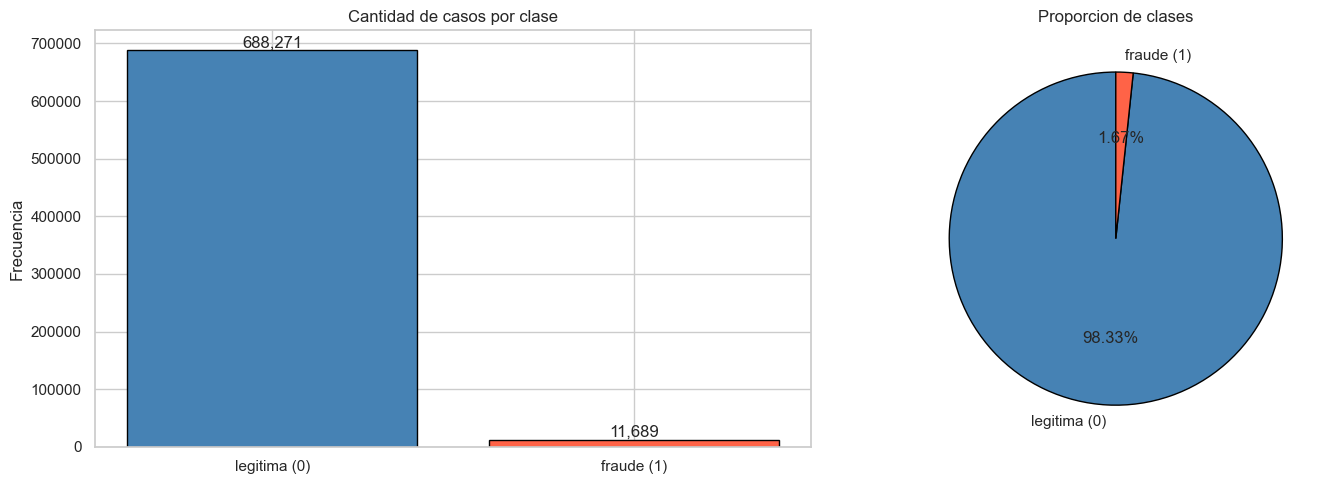

Tasa base (is_fraud = 1): 1.6700%  ->  1 fraude cada 60 transacciones


In [7]:
counts = train["y"].value_counts().sort_index()
tasa_base = train["y"].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(["legitima (0)", "fraude (1)"], counts.values, color=["steelblue", "tomato"], edgecolor="black")
axes[0].set_title("Cantidad de casos por clase")
axes[0].set_ylabel("Frecuencia")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

axes[1].pie(counts.values, labels=["legitima (0)", "fraude (1)"], autopct="%1.2f%%",
            colors=["steelblue", "tomato"], startangle=90,
            wedgeprops={"edgecolor": "black"})
axes[1].set_title("Proporcion de clases")
plt.tight_layout()
plt.show()

print(f"Tasa base (is_fraud = 1): {tasa_base:.4%}  ->  1 fraude cada {1 / tasa_base:.0f} transacciones")

Desbalance fuerte: 1,67 % de fraudes, uno cada 60 transacciones (11.689 positivos). Con ROC AUC no hace falta rebalancear, pero conviene usar folds estratificados para que cada uno tenga la misma tasa.

## 4. Variables Numéricas — Distribuciones

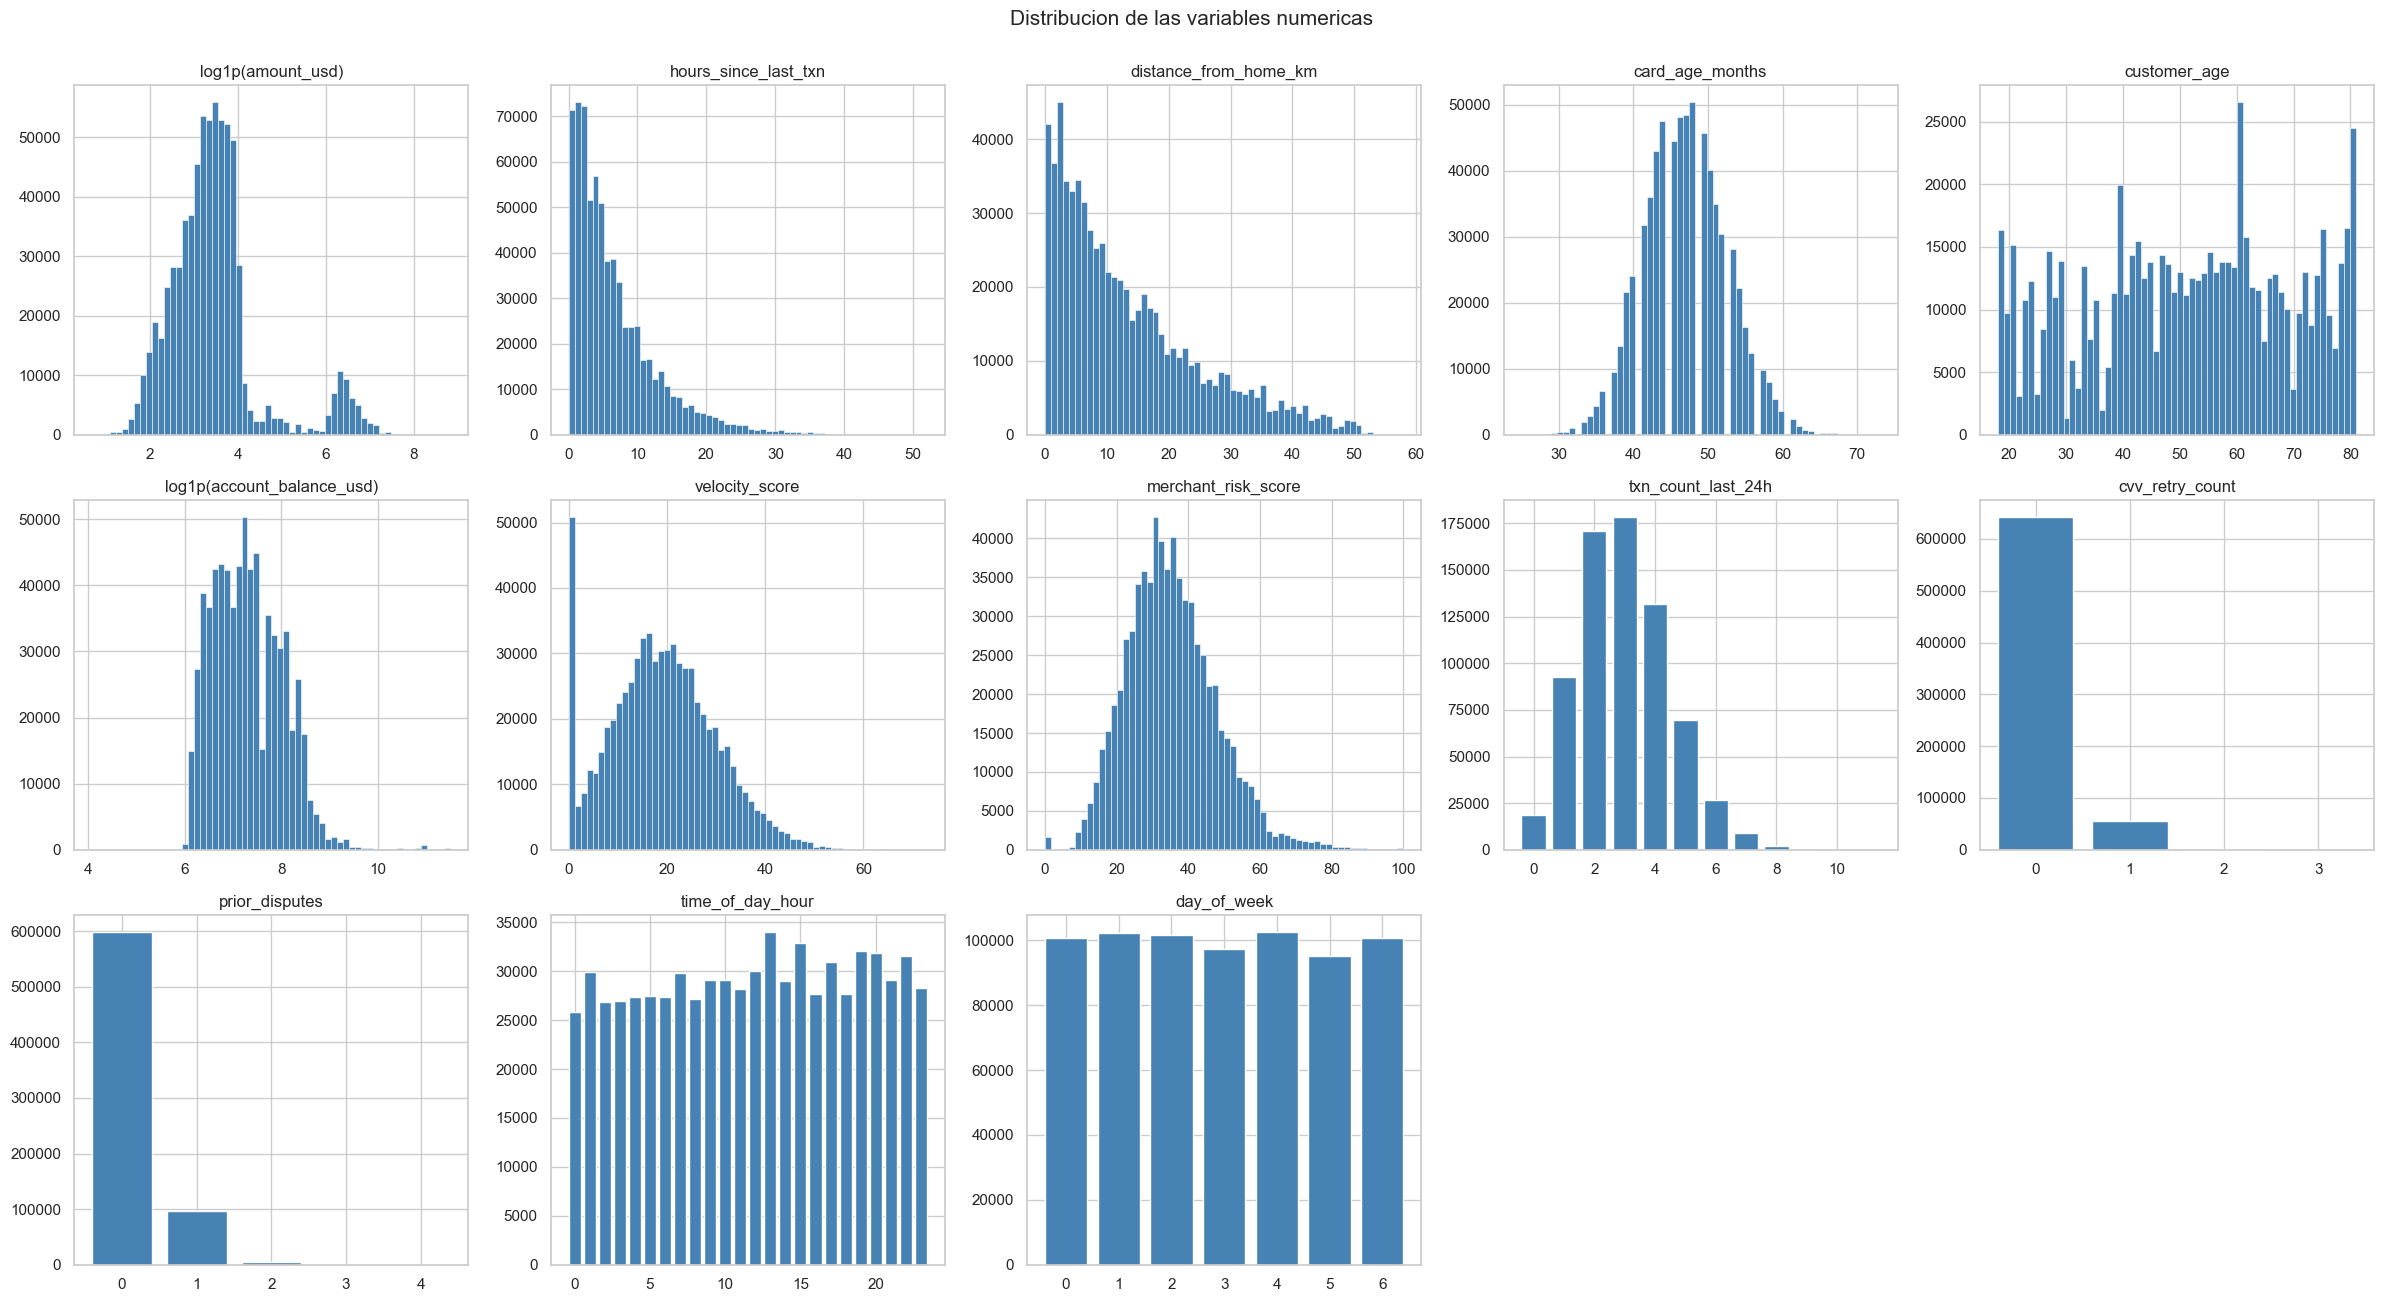

                         skew  pct_ceros
amount_usd              7.002      0.000
hours_since_last_txn    1.823      0.000
distance_from_home_km   1.060      0.000
card_age_months         0.133      0.000
customer_age           -0.141      0.000
account_balance_usd    14.436      0.000
velocity_score          0.260      0.069
merchant_risk_score     0.620      0.002
txn_count_last_24h      0.436      0.026
cvv_retry_count         3.319      0.917
prior_disputes          2.377      0.855
time_of_day_hour       -0.056      0.037
day_of_week             0.018      0.144


In [8]:
fig, axes = plt.subplots(3, 5, figsize=(24, 13))
for ax, col in zip(axes.ravel(), numericas):
    x = train[col]
    if col in discretas:
        vc = x.value_counts().sort_index()
        ax.bar(vc.index, vc.values, color="steelblue", edgecolor="white")
    else:
        sesgo = x.skew() > 2
        ax.hist(np.log1p(x) if sesgo else x, bins=60, color="steelblue", edgecolor="white", linewidth=0.4)
        col = f"log1p({col})" if sesgo else col
    ax.set_title(col)
for ax in axes.ravel()[len(numericas):]:
    ax.axis("off")
plt.suptitle("Distribucion de las variables numericas", fontsize=15, y=1.00)
plt.tight_layout()
plt.show()

print(train[numericas].agg(["skew", lambda s: (s == 0).mean()]).T
      .rename(columns={"<lambda>": "pct_ceros"}).round(3).to_string())

`amount_usd` (asimetría 7,0) y `account_balance_usd` (14,4) tienen colas muy largas y se grafican en log. `cvv_retry_count` y `prior_disputes` son casi siempre 0 (92 % y 86 %). La hora y el día de la semana son prácticamente uniformes.

## 5. Variables Numéricas vs Target

Tasa de fraude por decil (continuas) o por valor (discretas), en escala log: con una tasa base de
~1,7 % la escala lineal aplasta las diferencias entre niveles bajos.

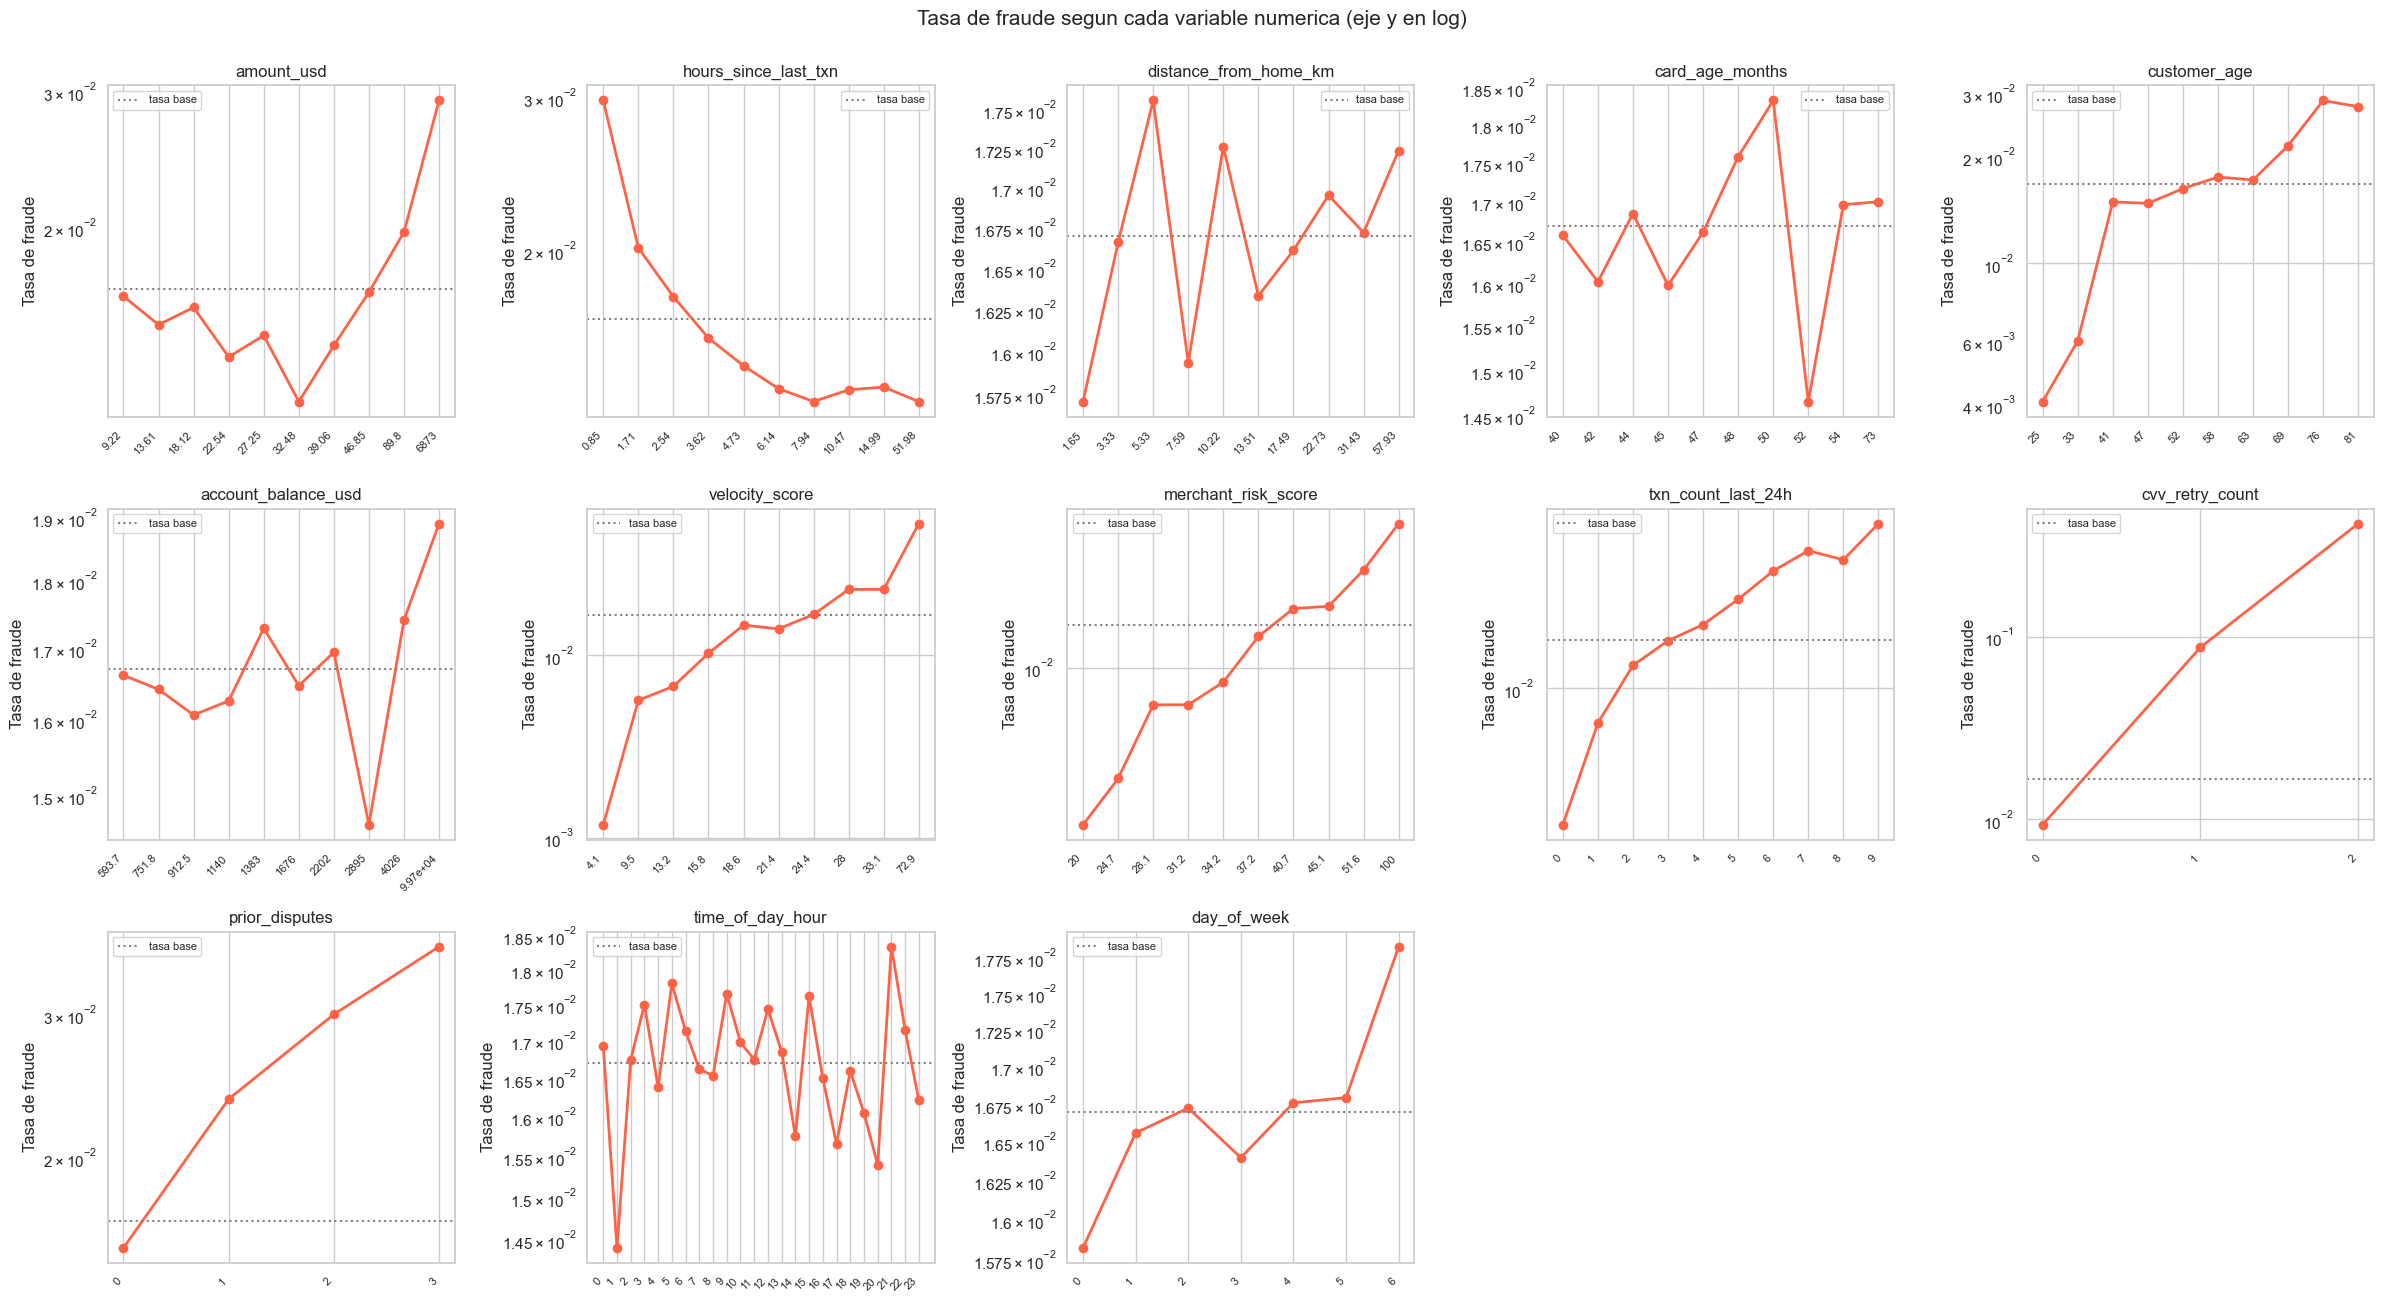

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(24, 13))
for ax, col in zip(axes.ravel(), numericas):
    if col in discretas:
        g = train.groupby(col)["y"].agg(["mean", "size"])
        g = g[g["size"] >= 100]
        etiquetas = [str(int(v)) for v in g.index]
    else:
        bins = pd.qcut(train[col], 10, duplicates="drop")
        g = train.groupby(bins, observed=True)["y"].agg(["mean", "size"])
        etiquetas = [f"{iv.right:.4g}" for iv in g.index]
    ax.plot(range(len(g)), g["mean"].values, marker="o", color="tomato", lw=2)
    ax.axhline(tasa_base, color="gray", ls=":", lw=1.5, label="tasa base")
    ax.set_yscale("log")
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel("Tasa de fraude")
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(numericas):]:
    ax.axis("off")
plt.suptitle("Tasa de fraude segun cada variable numerica (eje y en log)", fontsize=15, y=1.00)
plt.tight_layout()
plt.show()

In [10]:
# Detalle de las discretas con mas senal
for col in ["cvv_retry_count", "txn_count_last_24h", "prior_disputes"]:
    print(f"{col}\n{train.groupby(col)['y'].agg(['mean', 'size']).round(4).to_string()}\n")

cvv_retry_count
                   mean    size
cvv_retry_count                
0                0.0093  642088
1                0.0875   55942
2                0.4173    1905
3                0.3600      25

txn_count_last_24h
                      mean    size
txn_count_last_24h                
0                   0.0023   18462
1                   0.0069   92705
2                   0.0128  170757
3                   0.0166  178367
4                   0.0198  131869
5                   0.0259   69701
6                   0.0351   26488
7                   0.0436    8907
8                   0.0395    2252
9                   0.0582     378
10                  0.1231      65
11                  0.2222       9

prior_disputes
                  mean    size
prior_disputes                
0               0.0155  598396
1               0.0236   96365
2               0.0300    5032
3               0.0364     165
4               0.0000       2



In [11]:
# Forma fina de las continuas mas informativas: 20 cuantiles
for col in ["merchant_risk_score", "velocity_score", "customer_age"]:
    g = train.groupby(pd.qcut(train[col], 20, duplicates="drop"), observed=True)["y"].agg(["mean", "size"])
    print(f"{col}\n{g.round(4).to_string()}\n")

merchant_risk_score
                       mean   size
merchant_risk_score               
(-0.001, 16.5]       0.0009  35105
(16.5, 20.0]         0.0023  35651
(20.0, 22.6]         0.0023  34602
(22.6, 24.7]         0.0031  36515
(24.7, 26.4]         0.0060  33994
(26.4, 28.1]         0.0069  35650
(28.1, 29.7]         0.0058  33848
(29.7, 31.2]         0.0071  35710
(31.2, 32.6]         0.0058  35441
(32.6, 34.2]         0.0113  34736
(34.2, 35.6]         0.0157  33884
(35.6, 37.2]         0.0133  35155
(37.2, 39.0]         0.0173  36437
(39.0, 40.7]         0.0232  34433
(40.7, 42.7]         0.0178  33953
(42.7, 45.1]         0.0235  36180
(45.1, 47.9]         0.0302  33863
(47.9, 51.6]         0.0332  35420
(51.6, 57.3]         0.0374  35090
(57.3, 100.0]        0.0726  34293



velocity_score
                  mean   size
velocity_score               
(-0.001, 4.1]   0.0012  70275
(4.1, 7.3]      0.0055  35947
(7.3, 9.5]      0.0059  34279
(9.5, 11.4]     0.0059  34639
(11.4, 13.2]    0.0075  37659
(13.2, 14.5]    0.0099  32197
(14.5, 15.8]    0.0105  35365
(15.8, 17.3]    0.0139  36576
(17.3, 18.6]    0.0155  33199
(18.6, 20.1]    0.0141  37228
(20.1, 21.4]    0.0137  33706
(21.4, 22.9]    0.0165  36004
(22.9, 24.4]    0.0170  35086
(24.4, 26.0]    0.0218  33193
(26.0, 28.0]    0.0240  35270
(28.0, 30.3]    0.0218  35501
(30.3, 33.1]    0.0241  34459
(33.1, 37.4]    0.0422  34558
(37.4, 72.9]    0.0630  34819



customer_age
                  mean   size
customer_age                 
(17.999, 21.0]  0.0042  41238
(21.0, 25.0]    0.0039  29459
(25.0, 29.0]    0.0064  48039
(29.0, 33.0]    0.0054  24638
(33.0, 38.0]    0.0135  37246
(38.0, 41.0]    0.0165  31126
(41.0, 44.0]    0.0141  42408
(44.0, 47.0]    0.0155  34805
(47.0, 50.0]    0.0166  38004
(50.0, 52.0]    0.0156  23686
(52.0, 55.0]    0.0175  39838
(55.0, 58.0]    0.0174  40577
(58.0, 60.0]    0.0141  27164
(60.0, 63.0]    0.0193  40357
(63.0, 66.0]    0.0203  31613
(66.0, 69.0]    0.0225  34304
(69.0, 73.0]    0.0340  35037
(73.0, 76.0]    0.0240  38767
(76.0, 79.0]    0.0315  37155
(79.0, 81.0]    0.0216  24499



Las tres numéricas fuertes son **monótonas crecientes**: `merchant_risk_score` va de 0,09 % en el primer veintil a 7,3 % en el último (80×), `velocity_score` de 0,12 % a 6,3 % y `txn_count_last_24h` de 0,23 % con 0 transacciones a 4,4 % con 7. `cvv_retry_count` es un escalón: 0,9 % sin reintentos, 8,8 % con uno y 42 % con dos. `customer_age` tiene un salto alrededor de los 33 años (de ~0,5 % a ~1,5 %) y después sube despacio hasta ~3 %. `hours_since_last_txn` decrece (3 % con menos de una hora desde la anterior, ~1,1 % pasadas las 6 horas) y `amount_usd` tiene forma de U: mínimo en ~32 USD y salto a ~3 % en el último decil. `distance_from_home_km`, `card_age_months`, `account_balance_usd`, la hora y el día son planas.

## 6. Variables Binarias vs Target

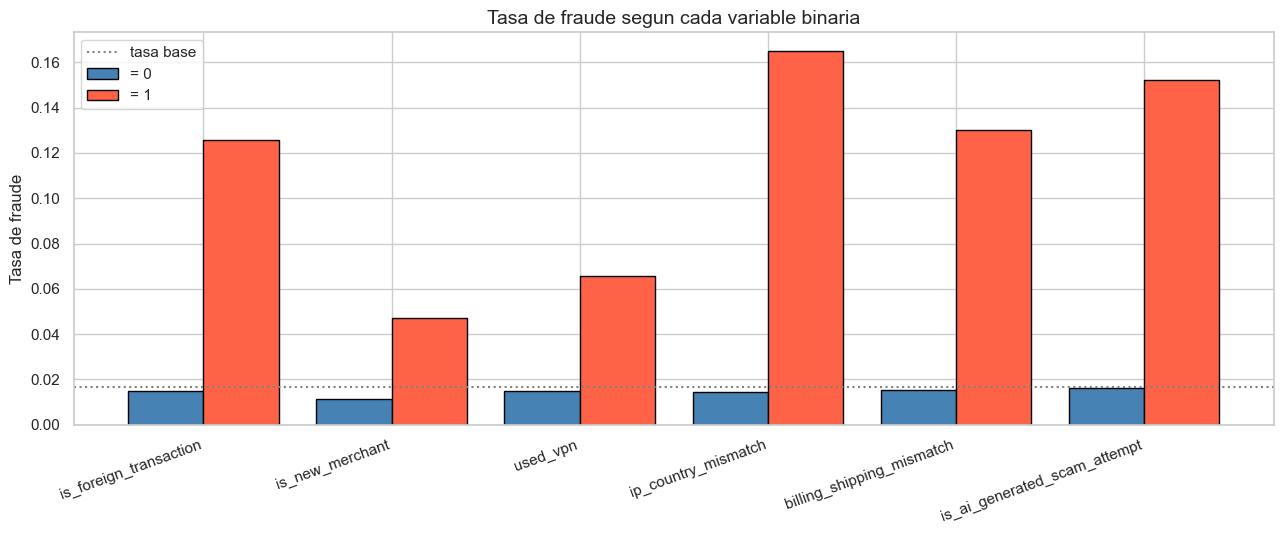

                               pct_1  tasa_si_0  tasa_si_1     lift
is_foreign_transaction        0.0173     0.0148     0.1257   8.5051
is_new_merchant               0.1525     0.0112     0.0473   4.2313
used_vpn                      0.0338     0.0150     0.0655   4.3688
ip_country_mismatch           0.0162     0.0143     0.1650  11.5645
billing_shipping_mismatch     0.0129     0.0152     0.1299   8.5361
is_ai_generated_scam_attempt  0.0033     0.0163     0.1522   9.3670



Cantidad de flags activos por fila:
     mean    size
0  0.0070  549155
1  0.0361  137966
2  0.1818   11455
3  0.5189    1268
4  0.8393     112
5  1.0000       4


In [12]:
res = pd.DataFrame({
    "pct_1": [train[c].mean() for c in binarias],
    "tasa_si_0": [train.loc[train[c] == 0, "y"].mean() for c in binarias],
    "tasa_si_1": [train.loc[train[c] == 1, "y"].mean() for c in binarias],
}, index=binarias)
res["lift"] = res["tasa_si_1"] / res["tasa_si_0"]

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(binarias))
ax.bar(x - 0.2, res["tasa_si_0"], 0.4, label="= 0", color="steelblue", edgecolor="black")
ax.bar(x + 0.2, res["tasa_si_1"], 0.4, label="= 1", color="tomato", edgecolor="black")
ax.axhline(tasa_base, color="gray", ls=":", lw=1.5, label="tasa base")
ax.set_xticks(x)
ax.set_xticklabels(binarias, rotation=20, ha="right")
ax.set_ylabel("Tasa de fraude")
ax.set_title("Tasa de fraude segun cada variable binaria", fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

print(res.round(4).to_string())

n_flags = train[binarias].sum(axis=1)
print("\nCantidad de flags activos por fila:")
print(train.groupby(n_flags)["y"].agg(["mean", "size"]).round(4).to_string())

Las seis binarias son raras (entre 0,3 % y 15 % de las filas) pero multiplican el riesgo: `ip_country_mismatch` lo multiplica por 11,6, `is_ai_generated_scam_attempt` por 9,4 y `is_foreign_transaction` y `billing_shipping_mismatch` por 8,5. Los flags se acumulan casi exactamente de forma aditiva en log-odds (~+1,6 por flag): la tasa pasa de 0,7 % sin flags a 3,6 %, 18 %, 52 % y 84 % con 1, 2, 3 y 4.

## 7. Variables Categóricas vs Target

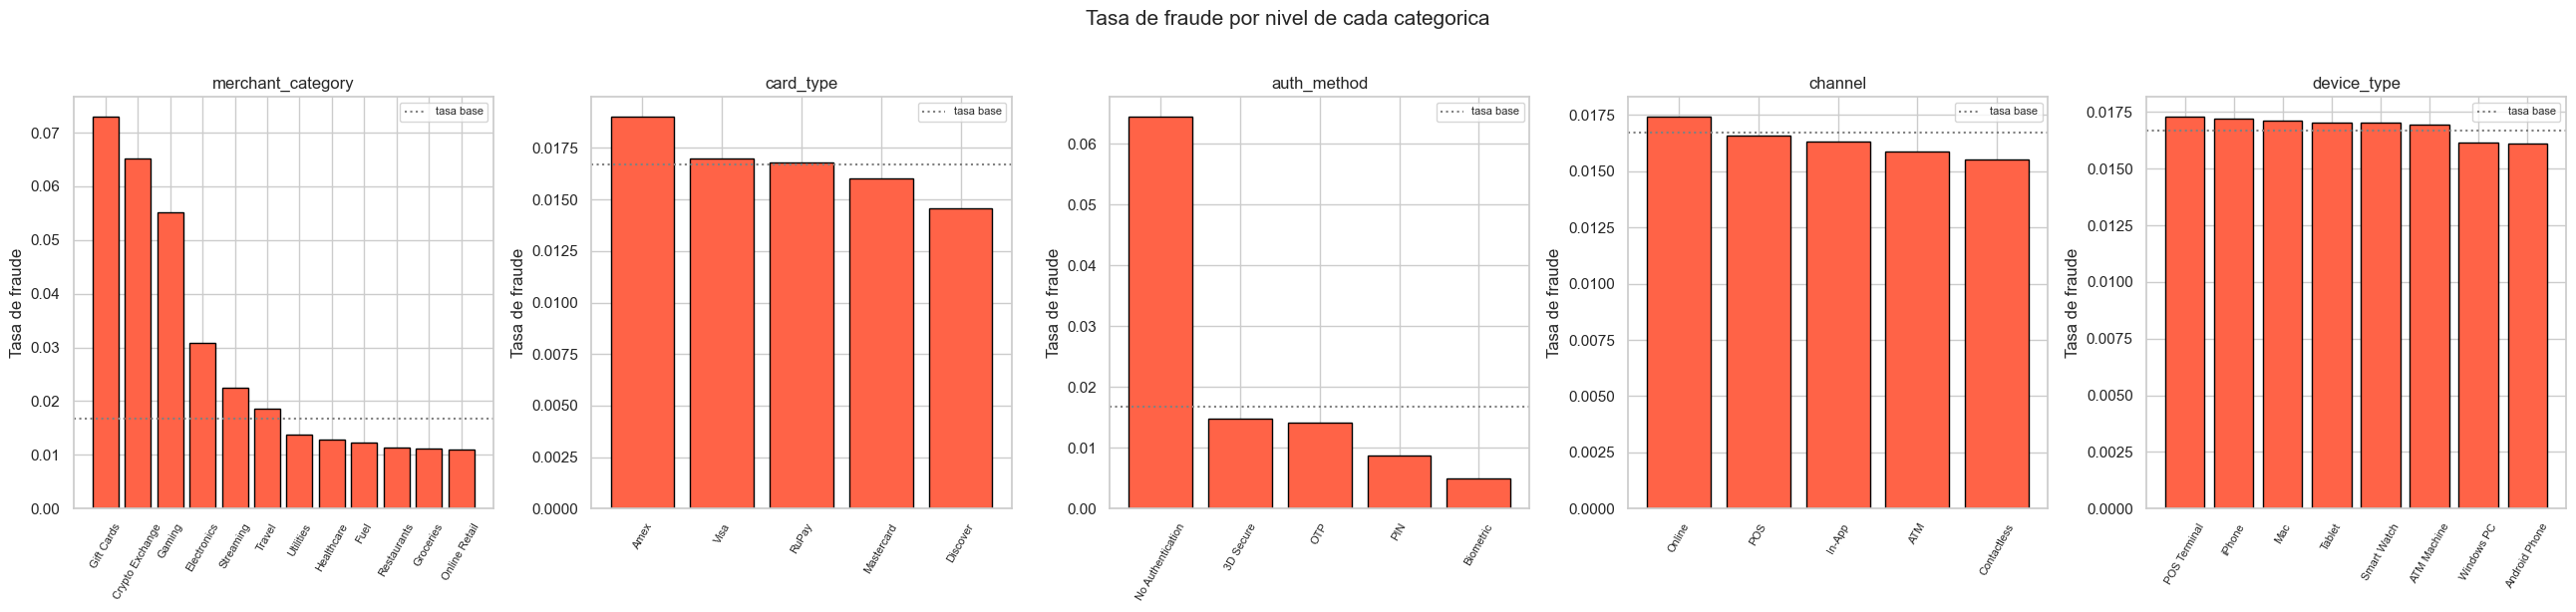

merchant_category
                     mean    size
merchant_category                
Gift Cards         0.0730    9456
Crypto Exchange    0.0653    5285
Gaming             0.0551   23784
Electronics        0.0308   48693
Streaming          0.0225   47196
Travel             0.0186   28715
Utilities          0.0138   42027
Healthcare         0.0129   35889
Fuel               0.0124   59880
Restaurants        0.0114  101360
Groceries          0.0111  142578
Online Retail      0.0111  155097

card_type
              mean    size
card_type                 
Amex        0.0190   45797
Visa        0.0170  345001
RuPay       0.0168   37070
Mastercard  0.0160  254857
Discover    0.0146   17235



auth_method
                     mean    size
auth_method                      
No Authentication  0.0644   67060
3D Secure          0.0147  210036
OTP                0.0141  175178
PIN                0.0087  154020
Biometric          0.0050   93666

channel
               mean    size
channel                    
Online       0.0174  273939
POS          0.0166  206465
In-App       0.0163   83716
ATM          0.0159   30220
Contactless  0.0155  105620



device_type
                 mean    size
device_type                  
POS Terminal   0.0173  113237
iPhone         0.0172  164691
Mac            0.0171   33973
Tablet         0.0170   27688
Smart Watch    0.0170   21106
ATM Machine    0.0170   20877
Windows PC     0.0161   80934
Android Phone  0.0161  237454



In [13]:
fig, axes = plt.subplots(1, 5, figsize=(26, 6))
for ax, col in zip(axes, categoricas):
    g = train.groupby(col)["y"].mean().sort_values(ascending=False)
    ax.bar(g.index.astype(str), g.values, color="tomato", edgecolor="black")
    ax.axhline(tasa_base, color="gray", ls=":", lw=1.5, label="tasa base")
    ax.set_title(col)
    ax.set_ylabel("Tasa de fraude")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.legend(fontsize=8)
plt.suptitle("Tasa de fraude por nivel de cada categorica", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

for col in categoricas:
    g = train.groupby(col)["y"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    print(f"{col}\n{g.round(4).to_string()}\n")

`auth_method` separa mucho: sin autenticación la tasa es 6,4 %, contra 0,5 % con biometría. En `merchant_category` hay un grupo de riesgo (Gift Cards 7,3 %, Crypto Exchange 6,5 %, Gaming 5,5 %) frente a rubros cotidianos en ~1,1 %. `card_type`, `channel` y `device_type` no se mueven de la tasa base.

## 8. Poder Discriminante — AUC Univariado

El AUC de cada variable usada **sola** como score, comparable con la métrica de la competencia.

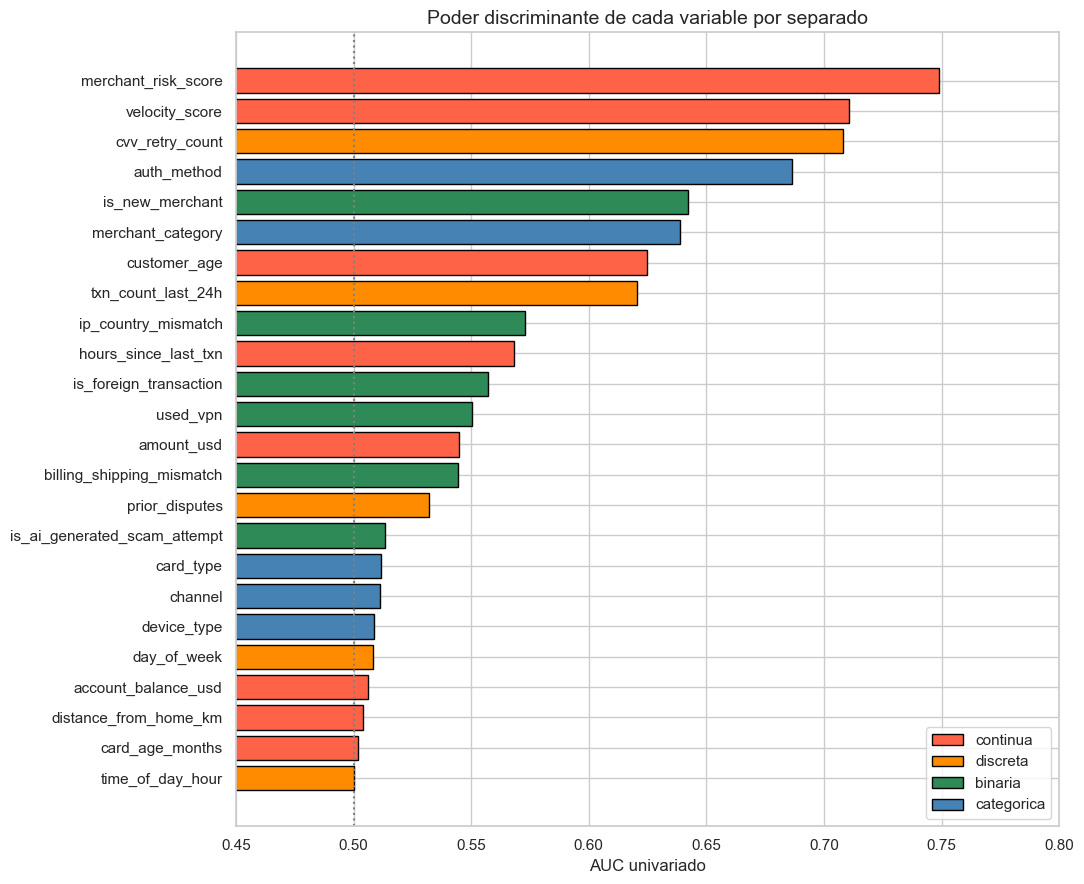

                    variable       tipo    auc signo
         merchant_risk_score   continua 0.7489     +
              velocity_score   continua 0.7108     +
             cvv_retry_count   discreta 0.7081     +
                 auth_method categorica 0.6866     +
             is_new_merchant    binaria 0.6422     +
           merchant_category categorica 0.6390     +
                customer_age   continua 0.6247     +
          txn_count_last_24h   discreta 0.6203     +
         ip_country_mismatch    binaria 0.5730     +
        hours_since_last_txn   continua 0.5682     -
      is_foreign_transaction    binaria 0.5574     +
                    used_vpn    binaria 0.5502     +
                  amount_usd   continua 0.5448     +
   billing_shipping_mismatch    binaria 0.5446     +
              prior_disputes   discreta 0.5322     +
is_ai_generated_scam_attempt    binaria 0.5136     +
                   card_type categorica 0.5119     +
                     channel categorica 0.5112

In [14]:
filas = []
for col in numericas + binarias:
    auc = roc_auc_score(train["y"], train[col])
    tipo = "continua" if col in continuas else "discreta" if col in discretas else "binaria"
    filas.append({"variable": col, "tipo": tipo, "auc": max(auc, 1 - auc), "signo": "+" if auc >= 0.5 else "-"})
for col in categoricas:
    # Se usa la tasa de target por nivel como score (equivale a ordenar por el nivel)
    score = train[col].map(train.groupby(col)["y"].mean())
    filas.append({"variable": col, "tipo": "categorica", "auc": roc_auc_score(train["y"], score), "signo": "+"})

poder = pd.DataFrame(filas).sort_values("auc", ascending=False).reset_index(drop=True)

paleta = {"continua": "tomato", "discreta": "darkorange", "binaria": "seagreen", "categorica": "steelblue"}
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(poder["variable"][::-1], poder["auc"][::-1],
        color=[paleta[t] for t in poder["tipo"][::-1]], edgecolor="black")
ax.axvline(0.5, color="gray", ls=":", lw=1.5)
ax.set_xlabel("AUC univariado")
ax.set_title("Poder discriminante de cada variable por separado", fontsize=14)
ax.set_xlim(0.45, 0.8)
ax.legend(handles=[Patch(facecolor=c, edgecolor="black", label=t) for t, c in paleta.items()])
plt.tight_layout()
plt.show()

print(poder.round(4).to_string(index=False))

`merchant_risk_score` es la mejor variable suelta (0,75), seguida de `velocity_score` (0,71), `cvv_retry_count` (0,71) y `auth_method` (0,69). Las binarias tienen AUC bajo (0,51-0,64) porque afectan a pocas filas, aunque cada una tiene un lift de 4-12×. Ocho variables están pegadas a 0,50: `card_type`, `channel`, `device_type`, `day_of_week`, `time_of_day_hour`, `account_balance_usd`, `distance_from_home_km` y `card_age_months`.

## 9. Interacciones

Se cruzan pares donde es esperable que el efecto de una variable dependa de la otra: el método de
autenticación con el rubro del comercio, el riesgo del comercio con que sea nuevo para el cliente, y
los reintentos de CVV con la velocidad de transacciones.

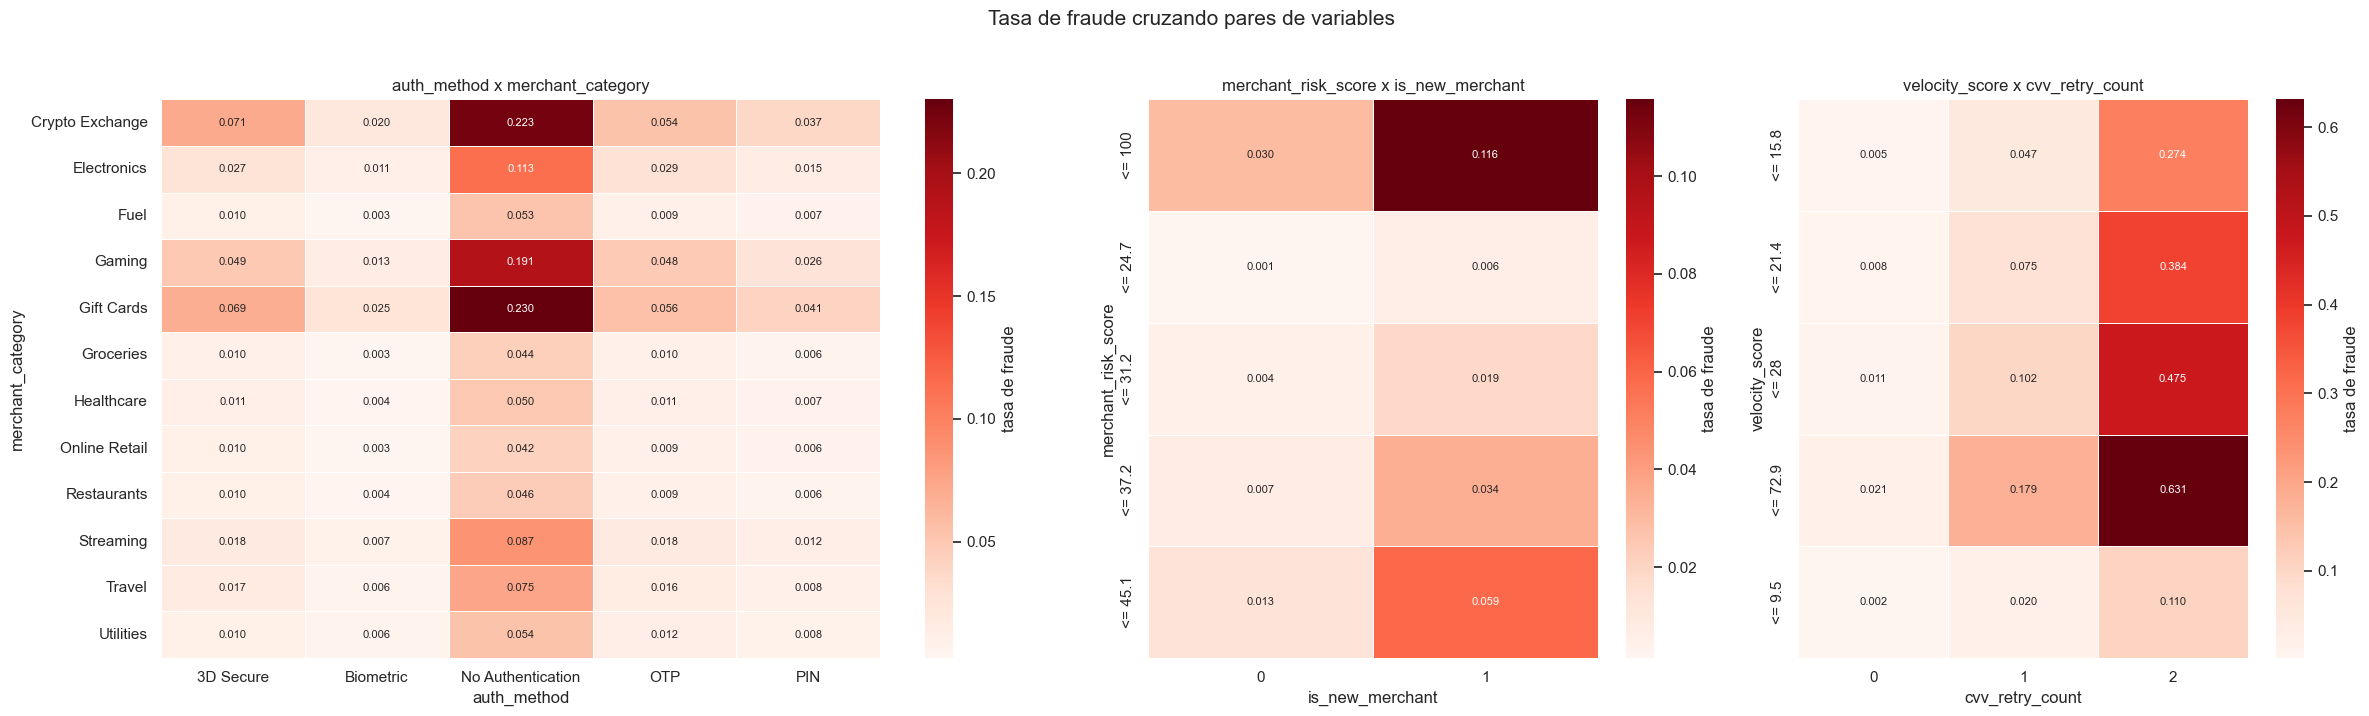

In [15]:
def tramo(s, q=5):
    return pd.qcut(s, q, duplicates="drop").apply(lambda iv: f"<= {iv.right:.4g}").astype(str)

cruces = {
    "auth_method x merchant_category": (train["merchant_category"], train["auth_method"]),
    "merchant_risk_score x is_new_merchant": (tramo(train["merchant_risk_score"]), train["is_new_merchant"]),
    "velocity_score x cvv_retry_count": (tramo(train["velocity_score"]), train["cvv_retry_count"].clip(upper=2)),
}

fig, axes = plt.subplots(1, 3, figsize=(24, 7), gridspec_kw={"width_ratios": [1.6, 1, 1]})
for ax, (nombre, (a, b)) in zip(axes, cruces.items()):
    piv = train["y"].groupby([a, b], observed=True).mean().unstack()
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="Reds", ax=ax, annot_kws={"size": 8},
                linewidths=0.5, linecolor="white", cbar_kws={"label": "tasa de fraude"})
    ax.set_title(nombre)
plt.suptitle("Tasa de fraude cruzando pares de variables", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [16]:
# Si el efecto fuera aditivo en log-odds, el delta entre dos columnas seria constante por fila.
MIN_POS = 20

def logit(p):
    p = p.clip(1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

for nombre, (a, b) in cruces.items():
    grp = train["y"].groupby([a, b], observed=True)
    tasa, pos, n = grp.mean().unstack(), grp.sum().unstack(), grp.size().unstack()
    c0, c1 = tasa.columns[0], tasa.columns[-1]
    dif = (logit(tasa[c1]) - logit(tasa[c0])).round(3)
    solido = (pos[[c0, c1]] >= MIN_POS).all(axis=1) & ((n - pos)[[c0, c1]] >= MIN_POS).all(axis=1)
    d = dif[solido]
    print(f"{nombre}")
    print(f"  delta log-odds ({c1} vs {c0}) por fila: {dif.to_dict()}")
    print(f"  rango del delta sobre las {len(d)} filas solidas: {d.max() - d.min():.3f}"
          f"   -> {'INTERACCION' if d.max() - d.min() > 0.6 else 'aproximadamente aditivo'}\n")

auth_method x merchant_category
  delta log-odds (PIN vs 3D Secure) por fila: {'Crypto Exchange': -0.68, 'Electronics': -0.643, 'Fuel': -0.419, 'Gaming': -0.646, 'Gift Cards': -0.548, 'Groceries': -0.509, 'Healthcare': -0.463, 'Online Retail': -0.455, 'Restaurants': -0.587, 'Streaming': -0.411, 'Travel': -0.734, 'Utilities': -0.302}
  rango del delta sobre las 12 filas solidas: 0.432   -> aproximadamente aditivo



merchant_risk_score x is_new_merchant
  delta log-odds (1 vs 0) por fila: {'<= 100': 1.452, '<= 24.7': 1.496, '<= 31.2': 1.466, '<= 37.2': 1.552, '<= 45.1': 1.522}
  rango del delta sobre las 5 filas solidas: 0.100   -> aproximadamente aditivo



velocity_score x cvv_retry_count
  delta log-odds (2 vs 0) por fila: {'<= 15.8': 4.416, '<= 21.4': 4.338, '<= 28': 4.394, '<= 72.9': 4.362, '<= 9.5': 4.183}
  rango del delta sobre las 5 filas solidas: 0.233   -> aproximadamente aditivo



**No aparecen interacciones**: en los tres cruces el delta de log-odds es casi constante entre filas (rango 0,10-0,43). Un comercio nuevo suma ~+1,5 en cualquier tramo de riesgo y dos reintentos de CVV suman ~+4,4 con cualquier velocidad. Junto con la acumulación de flags, apunta a un generador aditivo en log-odds.

## 10. Correlaciones

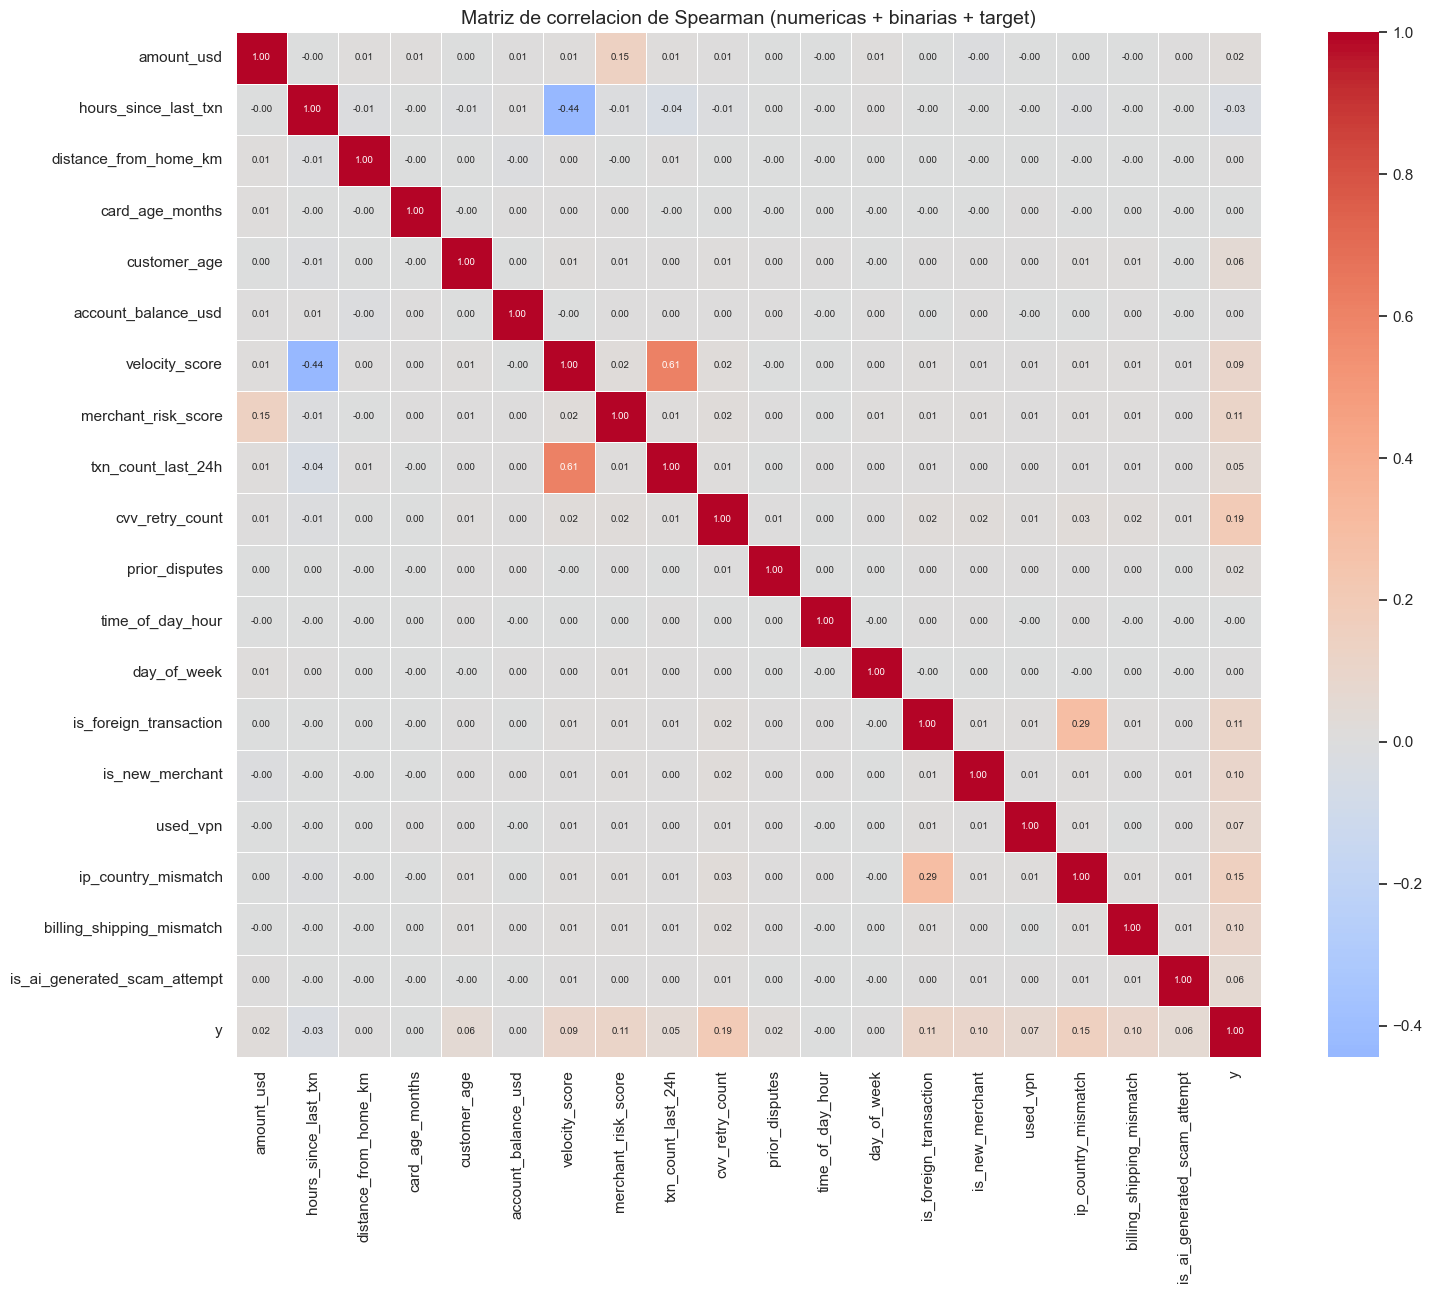

Pares de features mas correlacionados:
velocity_score          txn_count_last_24h           0.6132
hours_since_last_txn    velocity_score              -0.4443
is_foreign_transaction  ip_country_mismatch          0.2900
amount_usd              merchant_risk_score          0.1477
hours_since_last_txn    txn_count_last_24h          -0.0423
cvv_retry_count         ip_country_mismatch          0.0288
                        billing_shipping_mismatch    0.0220
merchant_risk_score     cvv_retry_count              0.0214


In [17]:
cols_corr = numericas + binarias + ["y"]
corr = train[cols_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
            linewidths=0.5, linecolor="white", square=True, annot_kws={"size": 7})
ax.set_title("Matriz de correlacion de Spearman (numericas + binarias + target)", fontsize=14)
plt.tight_layout()
plt.show()

sin_y = corr.drop(index="y", columns="y")
pares_corr = (sin_y.where(np.triu(np.ones(sin_y.shape, dtype=bool), k=1))
              .stack().sort_values(key=abs, ascending=False))
print("Pares de features mas correlacionados:")
print(pares_corr.head(8).round(4).to_string())

Features casi independientes. El único par fuerte es `velocity_score` con `txn_count_last_24h` (0,61), y `velocity_score` también correlaciona con `hours_since_last_txn` (-0,44). `is_foreign_transaction` e `ip_country_mismatch` se mueven juntas en parte (0,29).

## 11. Train vs Test

Comparación rápida de distribuciones para descartar drift entre los dos conjuntos.

In [18]:
filas = []
for col in numericas + binarias:
    filas.append({"variable": col, "media_train": train[col].mean(), "media_test": test[col].mean(),
                  "dif_en_std": (test[col].mean() - train[col].mean()) / train[col].std()})
for col in categoricas:
    p_tr = train[col].value_counts(normalize=True)
    p_te = test[col].value_counts(normalize=True)
    filas.append({"variable": col, "media_train": np.nan, "media_test": np.nan,
                  "dif_en_std": (p_te - p_tr).abs().max()})
drift = pd.DataFrame(filas)
print(drift.round(4).to_string(index=False))
print(f"\nMaxima diferencia absoluta: {drift['dif_en_std'].abs().max():.4f}")
print(f"Niveles de test que no aparecen en train: "
      f"{ {c: sorted(set(test[c]) - set(train[c])) for c in categoricas} }")

                    variable  media_train  media_test  dif_en_std
                  amount_usd      79.8931     79.9212      0.0001
        hours_since_last_txn       6.6337      6.6403      0.0010
       distance_from_home_km      13.5876     13.6029      0.0013
             card_age_months      46.8630     46.8407     -0.0040
                customer_age      51.4303     51.4243     -0.0003
         account_balance_usd    2064.9981   2071.4680      0.0019
              velocity_score      18.9294     18.9385      0.0008
         merchant_risk_score      35.2176     35.2174     -0.0000
          txn_count_last_24h       2.9841      2.9838     -0.0002
             cvv_retry_count       0.0855      0.0854     -0.0004
              prior_disputes       0.1528      0.1539      0.0030
            time_of_day_hour      11.7619     11.7469     -0.0022
                 day_of_week       2.9817      2.9713     -0.0052
      is_foreign_transaction       0.0173      0.0174      0.0008
          

Niveles de test que no aparecen en train: {'merchant_category': [], 'card_type': [], 'auth_method': [], 'channel': [], 'device_type': []}


Sin drift: la mayor diferencia de medias es 0,005 desvíos, las proporciones de las categóricas coinciden con una diferencia de 0,2 % como máximo y test no tiene niveles nuevos.

## 12. Conclusiones

- **Dataset limpio y grande**: 699.960 × 24 features, sin nulos ni duplicados.
- **Target muy desbalanceado**: 1,67 % de fraudes (11.689 positivos).
- **La señal más fuerte es `merchant_risk_score`** (AUC 0,75; la tasa va de 0,09 % a 7,3 % entre el primer y el último veintil). Detrás vienen `velocity_score` (0,71), `cvv_retry_count` (0,71) y `auth_method` (0,69).
- **`cvv_retry_count` es un escalón**: 0,9 % → 8,8 % → 42 % con 0, 1 y 2 reintentos.
- **Las binarias son raras pero muy potentes**: lift de 4-12× cada una, y se acumulan de forma aditiva en log-odds (84 % de fraude con 4 flags activos).
- **En las categóricas hay riesgo por rubro y por autenticación**: Gift Cards, Crypto y Gaming en 5,5-7,3 %; sin autenticación 6,4 % contra 0,5 % con biometría.
- **Ruido**: `card_type`, `channel`, `device_type`, hora, día, saldo, distancia y antigüedad de la tarjeta (AUC ≤ 0,51).
- **Los cruces probados son aditivos en log-odds** (rango del delta ≤ 0,43), lo que sugiere un generador logístico casi lineal.
- **Poca colinealidad**: sólo `velocity_score` con `txn_count_last_24h` (0,61).
- **Train y test tienen la misma distribución** (diferencias de 0,005 desvíos como máximo).